## 1 · Environment

In [1]:
%pip -q install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels xgboost tabulate

### 1.1 · Import everything in one cell

In [2]:
import warnings, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from xgboost import XGBRegressor
from google.colab import drive
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
OUT = Path('/content/tourism_outputs')
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
print('Imports ready. Results folder:', OUT)

Imports ready. Results folder: /content/tourism_outputs


## 2 · Mount Drive and load the CSV

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
CSV_PATH = '/content/drive/MyDrive/Srilanka Tourism Recovery/sri_lanka_tourism_data.csv'
csv_file = Path(CSV_PATH)
if not csv_file.is_file():
    raise FileNotFoundError(f'CSV not found at {CSV_PATH}. In Colab Files sidebar, right-click your CSV → Copy path.')
raw = pd.read_csv(csv_file, encoding='utf-8-sig')
print('Loaded:', csv_file, '| Shape:', raw.shape)
display(raw.head())

Loaded: /content/drive/MyDrive/Srilanka Tourism Recovery/sri_lanka_tourism_data.csv | Shape: (336, 7)


,Date,Year,Month,Country,Arrivals,Total_Monthly_Arrivals,Est_Revenue_MUSD
0,2022-01-01,2022,January,India,18111,82327,144.07
1,2022-01-01,2022,January,Russia,13172,82327,144.07
2,2022-01-01,2022,January,United Kingdom,8232,82327,144.07
3,2022-01-01,2022,January,Germany,6586,82327,144.07
4,2022-01-01,2022,January,China,5762,82327,144.07


## 3 · Validate and clean the data

In [5]:
def normalize_column(name):
    return re.sub(r'[^a-z0-9]+', '_', str(name).strip().lower()).strip('_')

df = raw.copy()
df.columns = [normalize_column(c) for c in df.columns]
df = df.rename(columns={'est_revenue_m_usd':'est_revenue_musd',
                         'estimated_revenue_musd':'est_revenue_musd',
                         'total_monthly_arrival':'total_monthly_arrivals',
                         'arrival':'arrivals'})
required = ['date','year','month','country','arrivals','total_monthly_arrivals','est_revenue_musd']
missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')
print('Schema verified:', required)

Schema verified: ['date', 'year', 'month', 'country', 'arrivals', 'total_monthly_arrivals', 'est_revenue_musd']


In [6]:
print('Missing before cleaning:')
display(df[required].isna().sum().to_frame('null_rows'))
print('Exact duplicated rows:', int(df.duplicated().sum()))
df = df.drop_duplicates().copy()

Missing before cleaning:


,null_rows
date,0
year,0
month,0
country,0
arrivals,0
total_monthly_arrivals,0
est_revenue_musd,0


Exact duplicated rows: 0


In [7]:
for c in ['arrivals','total_monthly_arrivals','est_revenue_musd']:
    cleaned = df[c].astype('string').str.replace(',', '', regex=False).str.replace('$','',regex=False)
    df[c] = pd.to_numeric(cleaned, errors='coerce').astype('float64')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['country'] = df['country'].astype('string').str.strip()
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df['month'] = df['month'].astype('string').str.strip().str.title()
from_parts = pd.to_datetime(df['year'].astype('Int64').astype('string')+'-'+df['month'],
                            format='%Y-%B', errors='coerce')
df['date'] = df['date'].fillna(from_parts).dt.to_period('M').dt.to_timestamp()
print('Types normalized.')

Types normalized.


In [8]:
bad = (df['date'].isna() | df['country'].isna() | df['country'].eq('') |
       df['arrivals'].isna() | df['arrivals'].lt(0))
print('Rows discarded (invalid essential fields):', int(bad.sum()))
df = df.loc[~bad].copy()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month_name()
df = df[df['year'].between(2022, 2026)].copy()
if df.empty: raise ValueError('No usable tourism records remain.')
if df.duplicated(['date','country']).any():
    display(df[df.duplicated(['date','country'], keep=False)])
    raise ValueError('Repeated country/month records need manual reconciliation.')
print('Clean country-month records:', len(df))
df.to_csv(OUT/'clean_country_month_data.csv', index=False)

Rows discarded (invalid essential fields): 0
Clean country-month records: 336


## 4 · Create the national monthly table (prevent double counting)

In [9]:
for c in ['total_monthly_arrivals','est_revenue_musd']:
    conflicts = df.groupby('date')[c].nunique(dropna=True)
    if conflicts.gt(1).any():
        raise ValueError(f'{c}: monthly values conflict on {list(conflicts[conflicts.gt(1)].index)}')
monthly = df.groupby('date', as_index=False).agg(
    total_arrivals=('total_monthly_arrivals','first'),
    estimated_revenue_musd=('est_revenue_musd','first'),
    covered_country_arrivals=('arrivals','sum'),
    reported_markets=('country','nunique')
).sort_values('date').reset_index(drop=True)
monthly['year'] = monthly.date.dt.year
monthly['month_num'] = monthly.date.dt.month
monthly['month'] = monthly.date.dt.month_name()
monthly['coverage_ratio'] = monthly.covered_country_arrivals / monthly.total_arrivals.replace(0,np.nan)
monthly['usd_per_arrival'] = 1e6 * monthly.estimated_revenue_musd / monthly.total_arrivals.replace(0,np.nan)
display(monthly.head())

,date,total_arrivals,estimated_revenue_musd,covered_country_arrivals,reported_markets,year,month_num,month,coverage_ratio,usd_per_arrival
0,2022-01-01,82327.0,144.07,82323.0,6,2022,1,January,0.999951,1749.972670
1,2022-02-01,96507.0,168.89,96504.0,6,2022,2,February,0.999969,1750.028495
2,2022-03-01,106124.0,185.72,106120.0,6,2022,3,March,0.999962,1750.028269
3,2022-04-01,62980.0,110.22,62977.0,6,2022,4,April,0.999952,1750.079390
4,2022-05-01,30207.0,52.86,30204.0,6,2022,5,May,0.999901,1749.925514


In [10]:
months_missing = pd.date_range(monthly.date.min(), monthly.date.max(), freq='MS').difference(monthly.date)
print('Period:', monthly.date.min().date(), 'to', monthly.date.max().date())
print('Missing months:', list(months_missing.strftime('%Y-%m')))
print('Country coverage ratio summary:')
display(monthly.coverage_ratio.describe().to_frame('value'))
if ((monthly.coverage_ratio > 1.01) | (monthly.coverage_ratio < 0.8)).any():
    print('CAUTION: Some source-country sums differ substantially from national arrivals.')
monthly.to_csv(OUT/'national_monthly_summary.csv',index=False)

Period: 2022-01-01 to 2026-08-01
Missing months: []
Country coverage ratio summary:


,value
count,56.000000
mean,0.999977
std,0.000027
min,0.999878
25%,0.999969
50%,0.999981
75%,1.000000
max,1.000000


## 5 · Descriptive analysis: arrivals and earnings

In [11]:
annual = monthly.groupby('year', as_index=False).agg(
    arrivals=('total_arrivals','sum'),
    estimated_earnings_musd=('estimated_revenue_musd','sum'),
    observed_months=('date','size'))
annual['period'] = np.where(annual.observed_months.eq(12), 'complete year', 'partial year')
display(annual)
annual.to_csv(OUT/'annual_summary.csv',index=False)

,year,arrivals,estimated_earnings_musd,observed_months,period
0,2022,719602.0,1259.31,12,complete year
1,2023,1487303.0,2602.79,12,complete year
2,2024,2099073.0,3673.38,12,complete year
3,2025,2303000.0,4030.25,12,complete year
4,2026,1638000.0,2866.50,8,partial year


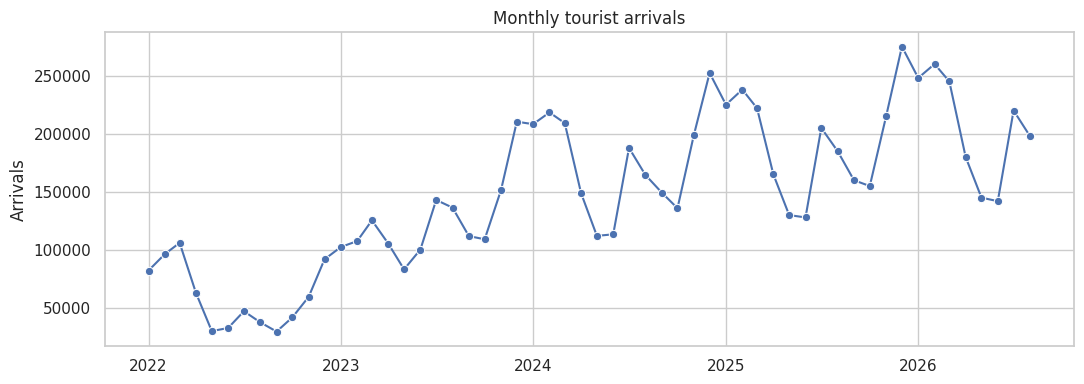

In [12]:
fig, ax = plt.subplots(figsize=(11,4))
sns.lineplot(data=monthly,x='date',y='total_arrivals',marker='o',ax=ax)
ax.set(title='Monthly tourist arrivals',xlabel='',ylabel='Arrivals')
plt.tight_layout(); plt.savefig(OUT/'arrivals_trend.png',dpi=180); plt.show()

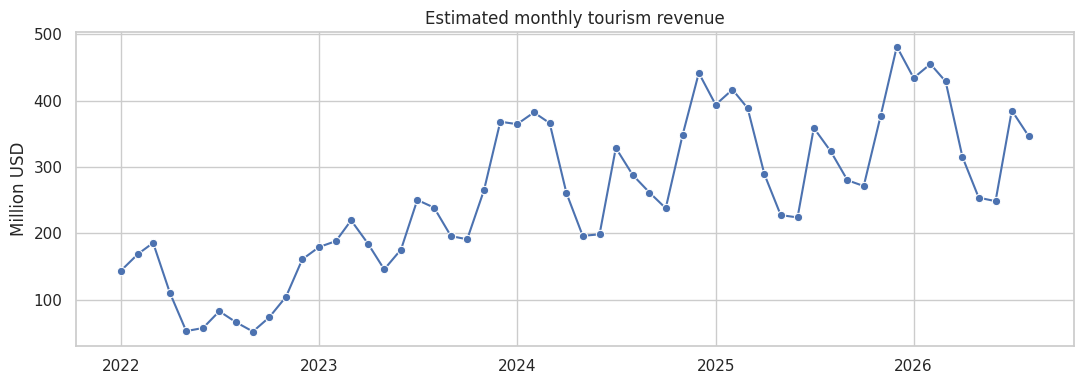

In [13]:
fig, ax = plt.subplots(figsize=(11,4))
sns.lineplot(data=monthly,x='date',y='estimated_revenue_musd',marker='o',ax=ax)
ax.set(title='Estimated monthly tourism revenue',xlabel='',ylabel='Million USD')
plt.tight_layout(); plt.savefig(OUT/'estimated_revenue_trend.png',dpi=180); plt.show()

## 6 · Recovery: same-month year-over-year growth

In [14]:
prev = monthly[['date','total_arrivals']].copy()
prev['date'] = prev['date'] + pd.DateOffset(years=1)
prev = prev.rename(columns={'total_arrivals':'previous_year_arrivals'})
monthly = monthly.merge(prev, on='date', how='left')
monthly['yoy_pct'] = 100*(monthly.total_arrivals / monthly.previous_year_arrivals.replace(0,np.nan)-1)
display(monthly[['date','total_arrivals','yoy_pct']].tail(18))

,date,total_arrivals,yoy_pct
38,2025-03-01,222000.0,6.128186
39,2025-04-01,165000.0,10.837190
40,2025-05-01,130000.0,15.938927
41,2025-06-01,128000.0,12.805147
42,2025-07-01,205000.0,9.152867
43,2025-08-01,185000.0,12.387537
44,2025-09-01,160000.0,7.063515
45,2025-10-01,155000.0,14.048577
46,2025-11-01,215000.0,8.173924
47,2025-12-01,275000.0,8.997226


In [15]:
ytd_rows=[]
for year in sorted(monthly.year.unique()):
    recent=monthly.loc[monthly.year.eq(year)].set_index('month_num').total_arrivals
    previous=monthly.loc[monthly.year.eq(year-1)].set_index('month_num').total_arrivals
    common=recent.index.intersection(previous.index)
    if len(common):
        p=previous.loc[common].sum()
        ytd_rows.append({'year':int(year),'compared_with':int(year-1),'matching_months':len(common),
                         'growth_pct':100*(recent.loc[common].sum()/p-1) if p else np.nan})
ytd=pd.DataFrame(ytd_rows)
display(ytd)
ytd.to_csv(OUT/'matched_month_yoy.csv',index=False)

,year,compared_with,matching_months,growth_pct
0,2023,2022,12,106.684111
1,2024,2023,12,41.132842
2,2025,2024,12,9.715098
3,2026,2025,8,9.345794


## 7 · Origin-country rankings and market concentration

In [16]:
country_summary=df.groupby('country',as_index=False).agg(
    arrivals=('arrivals','sum'),months_recorded=('date','nunique')).sort_values('arrivals',ascending=False)
country_summary['share_of_recorded_pct']=100*country_summary.arrivals/country_summary.arrivals.sum()
country_summary['coverage_months_pct']=100*country_summary.months_recorded/monthly.date.nunique()
display(country_summary.head(12))
country_summary.to_csv(OUT/'country_rankings.csv',index=False)
print('Market shares use recorded countries; completeness varies by country.')

,country,arrivals,months_recorded,share_of_recorded_pct,coverage_months_pct
3,Other Countries,3051362.0,56,37.000248,100.0
2,India,1814316.0,56,22.000058,100.0
4,Russia,1319501.0,56,16.000024,100.0
5,United Kingdom,824680.0,56,9.999916,100.0
1,Germany,659742.0,56,7.999909,100.0
0,China,577268.0,56,6.999844,100.0


Market shares use recorded countries; completeness varies by country.


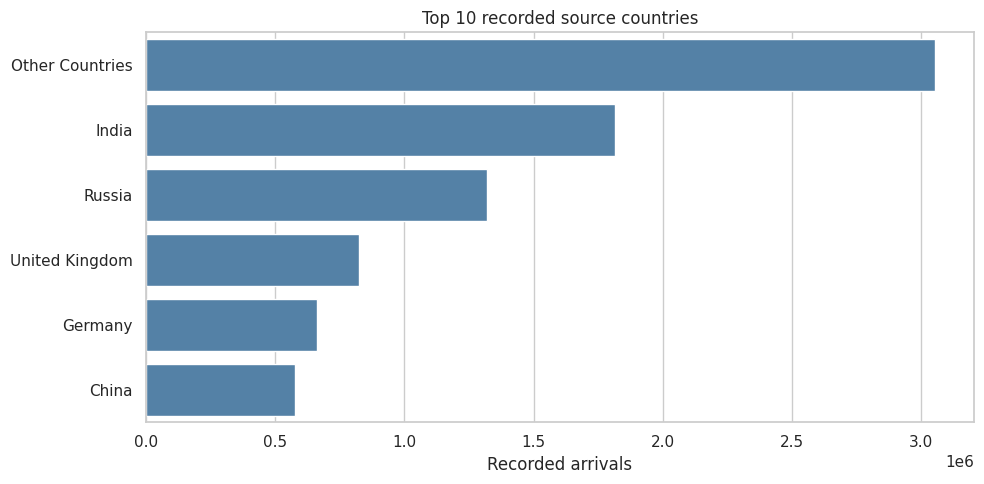

In [17]:
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=country_summary.head(10),x='arrivals',y='country',color='steelblue',ax=ax)
ax.set(title='Top 10 recorded source countries',xlabel='Recorded arrivals',ylabel='')
plt.tight_layout();plt.savefig(OUT/'top_countries.png',dpi=180);plt.show()

In [18]:
country_month=df.merge(monthly[['date','covered_country_arrivals']],on='date')
country_month['share']=country_month.arrivals / country_month.covered_country_arrivals.replace(0,np.nan)
hhi=country_month.groupby('date')['share'].apply(lambda s: (s**2).sum()).rename('hhi').reset_index()
print('HHI is a concentration index (higher = more concentrated among reported markets).')
display(hhi.describe())
hhi.to_csv(OUT/'market_concentration_hhi.csv',index=False)

HHI is a concentration index (higher = more concentrated among reported markets).


,date,hhi
count,56,56.000000
mean,2024-04-16 04:17:08.571428608,0.232203
min,2022-01-01 00:00:00,0.232200
25%,2023-02-22 00:00:00,0.232200
50%,2024-04-16 00:00:00,0.232202
75%,2025-06-08 12:00:00,0.232204
max,2026-08-01 00:00:00,0.232217
std,NaN,0.000004


## 8 · Seasonality

In [19]:
season=monthly.groupby('month_num',as_index=False).agg(
    mean_arrivals=('total_arrivals','mean'),median_arrivals=('total_arrivals','median'),
    observations=('total_arrivals','size'))
season['month']=pd.to_datetime(season.month_num,format='%m').dt.month_name()
display(season)

,month_num,mean_arrivals,median_arrivals,observations,month
0,1,173225.00,208253.0,5,January
1,2,184099.20,218350.0,5,February
2,3,181560.00,209181.0,5,March
3,4,132469.00,148867.0,5,April
4,5,100128.80,112128.0,5,May
5,6,103342.80,113470.0,5,June
6,7,160628.40,187810.0,5,July
7,8,144354.80,164609.0,5,August
8,9,112796.00,130691.0,4,September
9,10,110533.00,122553.0,4,October


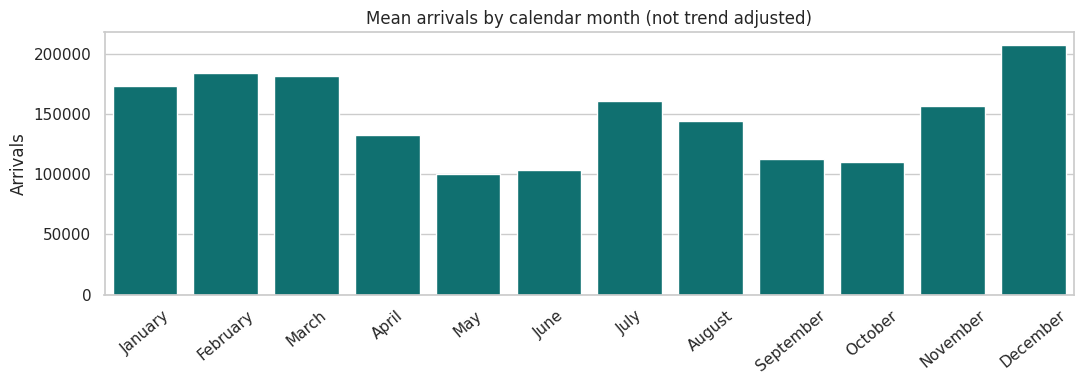

In [20]:
fig,ax=plt.subplots(figsize=(11,4))
sns.barplot(data=season,x='month',y='mean_arrivals',color='teal',ax=ax)
ax.tick_params(axis='x',rotation=40)
ax.set(title='Mean arrivals by calendar month (not trend adjusted)',ylabel='Arrivals',xlabel='')
plt.tight_layout();plt.savefig(OUT/'seasonality.png',dpi=180);plt.show()

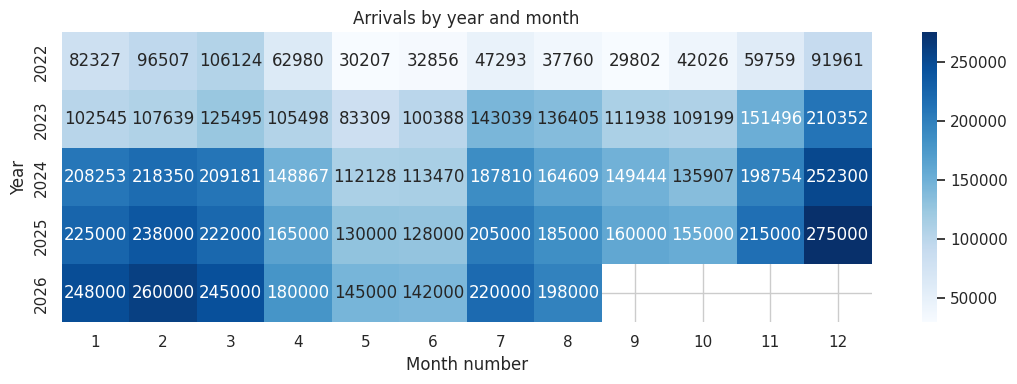

In [21]:
pivot = monthly.pivot(index='year', columns='month_num', values='total_arrivals')
pivot = pivot.apply(pd.to_numeric, errors='coerce').astype('float64')
fig,ax=plt.subplots(figsize=(11,4))
sns.heatmap(pivot,annot=True,fmt='.0f',cmap='Blues',mask=pivot.isna(),ax=ax)
ax.set(title='Arrivals by year and month',xlabel='Month number',ylabel='Year')
plt.tight_layout();plt.savefig(OUT/'year_month_heatmap.png',dpi=180);plt.show()

## 9 · Revenue relationships and statistics

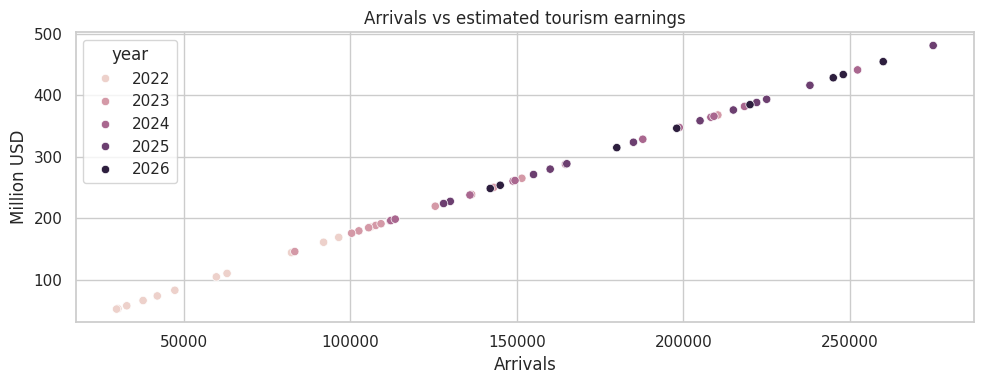

In [22]:
fig,ax=plt.subplots(figsize=(10,4))
sns.scatterplot(data=monthly,x='total_arrivals',y='estimated_revenue_musd',hue='year',ax=ax)
ax.set(title='Arrivals vs estimated tourism earnings',xlabel='Arrivals',ylabel='Million USD')
plt.tight_layout();plt.savefig(OUT/'revenue_scatter.png',dpi=180);plt.show()

In [23]:
valid=monthly[['total_arrivals','estimated_revenue_musd']].dropna()
if len(valid)>=3 and valid.nunique().min()>1:
    pearson_r,pearson_p=stats.pearsonr(valid.total_arrivals,valid.estimated_revenue_musd)
    spearman_r,spearman_p=stats.spearmanr(valid.total_arrivals,valid.estimated_revenue_musd)
    print(f'Pearson r={pearson_r:.3f}, p={pearson_p:.4g}')
    print(f'Spearman rho={spearman_r:.3f}, p={spearman_p:.4g}')
else:
    print('Insufficient varied observations for correlations.')
print('Correlation does not demonstrate causation.')

Pearson r=1.000, p=7.168e-256
Spearman rho=1.000, p=0
Correlation does not demonstrate causation.


## 10 · Forecast preparation (leakage-safe features)

In [24]:
ts=monthly.set_index('date').total_arrivals.sort_index().asfreq('MS').astype('float64')
if ts.isna().any():
    valid_segment=ts.notna().ne(ts.notna().shift()).cumsum()
    ts=ts[valid_segment.eq(valid_segment.iloc[-1])]
    print('Internal missing months: using only the latest contiguous segment.')
print('Forecast observations:',len(ts),'|',ts.index.min().date(),'to',ts.index.max().date())

Forecast observations: 56 | 2022-01-01 to 2026-08-01


In [25]:
def build_features(series):
    x=pd.DataFrame(index=series.index)
    x['trend']=np.arange(len(series))
    x['month_sin']=np.sin(2*np.pi*series.index.month/12)
    x['month_cos']=np.cos(2*np.pi*series.index.month/12)
    for lag in (1,2,3,6,12): x[f'lag_{lag}']=series.shift(lag)
    x['rolling_mean_3']=series.shift(1).rolling(3).mean()
    x['rolling_mean_6']=series.shift(1).rolling(6).mean()
    return x

X=build_features(ts)
FEATURES=X.columns.tolist()
display(X.tail(3))

,trend,month_sin,month_cos,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6
date,,,,,,,,,,
2026-06-01,53,1.224647e-16,-1.000000,145000.0,180000.0,245000.0,275000.0,128000.0,190000.000000,225500.000000
2026-07-01,54,-5.000000e-01,-0.866025,142000.0,145000.0,180000.0,248000.0,205000.0,155666.666667,203333.333333
2026-08-01,55,-8.660254e-01,-0.500000,220000.0,142000.0,145000.0,260000.0,185000.0,169000.000000,198666.666667


In [26]:
HOLDOUT=6
MIN_TRAIN=30
if len(ts)<MIN_TRAIN+HOLDOUT:
    raise ValueError(f'Need at least {MIN_TRAIN+HOLDOUT} contiguous monthly observations for fair evaluation.')
origin_positions=range(len(ts)-HOLDOUT,len(ts))
print('Walk-forward test:',ts.index[-HOLDOUT].strftime('%Y-%m'),'to',ts.index[-1].strftime('%Y-%m'))
print('Each model is retrained with available historical months only.')

Walk-forward test: 2026-03 to 2026-08
Each model is retrained with available historical months only.


### Helper: shared evaluation loop (one-month-ahead, expanding window)

In [27]:
def run_ml_walkforward(name, estimator):
    rows=[]
    for i in origin_positions:
        date=ts.index[i]
        train=X.iloc[:i].assign(y=ts.iloc[:i]).dropna()
        test_x=X.iloc[[i]][FEATURES]
        if test_x.isna().any().any(): raise ValueError(f'Missing features for {date:%Y-%m}')
        fitted=clone(estimator)
        fitted.fit(train[FEATURES],train.y)
        prediction=max(0,float(fitted.predict(test_x)[0]))
        rows.append({'date':date,'model':name,'actual':float(ts.iloc[i]),'prediction':prediction})
    return pd.DataFrame(rows)

def score_predictions(result):
    good=result.dropna(subset=['actual','prediction'])
    y=good.actual.to_numpy(); pred=good.prediction.to_numpy()
    if len(good)!=HOLDOUT: raise ValueError('Incomplete test window: results are not comparable.')
    denom=np.maximum(np.abs(y)+np.abs(pred),1e-8)
    return {'model':good.model.iloc[0], 'MAE':mean_absolute_error(y,pred),
            'RMSE':np.sqrt(mean_squared_error(y,pred)),
            'sMAPE_pct':np.mean(200*np.abs(y-pred)/denom),
            'R2':r2_score(y,pred), 'test_months':len(good)}

model_results={}
model_warnings={}
print('Shared evaluation helpers ready.')

Shared evaluation helpers ready.


## 11 · Model A — Seasonal Naive baseline

In [28]:
naive_rows=[]
for i in origin_positions:
    naive_rows.append({'date':ts.index[i],'model':'Seasonal Naive',
                       'actual':float(ts.iloc[i]),'prediction':float(ts.iloc[i-12])})
model_results['Seasonal Naive']=pd.DataFrame(naive_rows)
display(pd.DataFrame([score_predictions(model_results['Seasonal Naive'])]))

,model,MAE,RMSE,sMAPE_pct,R2,test_months
0,Seasonal Naive,15833.333333,16170.961629,8.945426,0.813244,6


## 12 · Model B — Ridge Regression

In [29]:
ridge=Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=10.0))])
model_results['Ridge Regression']=run_ml_walkforward('Ridge Regression',ridge)
display(pd.DataFrame([score_predictions(model_results['Ridge Regression'])]))

,model,MAE,RMSE,sMAPE_pct,R2,test_months
0,Ridge Regression,20741.431678,22830.05548,11.201183,0.627765,6


## 13 · Model C — Random Forest

In [30]:
rf=RandomForestRegressor(n_estimators=200,max_depth=5,min_samples_leaf=2,random_state=SEED,n_jobs=-1)
model_results['Random Forest']=run_ml_walkforward('Random Forest',rf)
display(pd.DataFrame([score_predictions(model_results['Random Forest'])]))

,model,MAE,RMSE,sMAPE_pct,R2,test_months
0,Random Forest,8687.642586,10054.072008,4.769265,0.927808,6


## 14 · Model D — XGBoost

In [31]:
xgb=XGBRegressor(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.9,
                 colsample_bytree=0.9,objective='reg:squarederror',random_state=SEED,n_jobs=2,verbosity=0)
model_results['XGBoost']=run_ml_walkforward('XGBoost',xgb)
display(pd.DataFrame([score_predictions(model_results['XGBoost'])]))

,model,MAE,RMSE,sMAPE_pct,R2,test_months
0,XGBoost,10543.091146,10982.922905,5.698513,0.913853,6


## 15 · Model E — SARIMA

In [32]:
SARIMA_CANDIDATES = [
    ((1, 1, 0), (0, 1, 0, 12)),
    ((0, 1, 1), (0, 1, 0, 12)),
    ((1, 1, 0), (1, 0, 0, 12)),
    ((0, 1, 1), (0, 0, 1, 12)),
    ((0, 1, 0), (0, 1, 0, 12)),
]

def fit_stable_sarima(history):
    candidates = []
    for order, seasonal in SARIMA_CANDIDATES:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                fitted = SARIMAX(history.astype(float), order=order,
                                seasonal_order=seasonal, trend='n',
                                enforce_stationarity=False,
                                enforce_invertibility=False).fit(disp=False, maxiter=400)
            good = bool(fitted.mle_retvals.get('converged', False))
            next_value = float(np.asarray(fitted.forecast(1)).ravel()[0])
            if good and np.isfinite(next_value) and np.isfinite(fitted.aic):
                candidates.append((float(fitted.aic), order, seasonal, fitted))
        except (ValueError, np.linalg.LinAlgError, FloatingPointError):
            continue
    return min(candidates, key=lambda item: item[0]) if candidates else None

print('Candidate SARIMA specifications:', len(SARIMA_CANDIDATES))

Candidate SARIMA specifications: 5


In [33]:
sarima_rows = []
for i in origin_positions:
    date = ts.index[i]
    selected = fit_stable_sarima(ts.iloc[:i])
    if selected is None:
        pred = float(ts.iloc[i-12])
        method, spec = 'seasonal_naive_fallback', 'previous-year month'
    else:
        _, order, seasonal, fitted = selected
        pred = max(0.0, float(np.asarray(fitted.forecast(1)).ravel()[0]))
        method, spec = 'converged_sarima', f'{order} x {seasonal}'
    sarima_rows.append({'date':date, 'model':'SARIMA + seasonal fallback',
                        'actual':float(ts.iloc[i]), 'prediction':pred,
                        'forecast_method':method, 'sarima_spec':spec})
model_results['SARIMA + seasonal fallback'] = pd.DataFrame(sarima_rows)
sarima_detail = model_results['SARIMA + seasonal fallback']
print('Reliable SARIMA fits:', (sarima_detail.forecast_method=='converged_sarima').sum(),
      '/', HOLDOUT)
print('Explicit baseline fallbacks:', (sarima_detail.forecast_method=='seasonal_naive_fallback').sum())
display(sarima_detail[['date','actual','prediction','forecast_method','sarima_spec']])
print('NOTE: A fallback prediction is NOT a converged SARIMA forecast.')

Reliable SARIMA fits: 6 / 6
Explicit baseline fallbacks: 0


,date,actual,prediction,forecast_method,sarima_spec
0,2026-03-01,245000.0,243897.184015,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"
1,2026-04-01,180000.0,188118.981137,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"
2,2026-05-01,145000.0,144130.748677,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"
3,2026-06-01,142000.0,143092.023567,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"
4,2026-07-01,220000.0,218883.932161,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"
5,2026-08-01,198000.0,200118.504032,converged_sarima,"(0, 1, 1) x (0, 1, 0, 12)"


NOTE: A fallback prediction is NOT a converged SARIMA forecast.


In [34]:
all_preds = pd.concat(model_results.values(), ignore_index=True)
comparison = pd.DataFrame([score_predictions(frame) for frame in model_results.values()])
comparison = comparison.sort_values('MAE').reset_index(drop=True)
comparison['R2'] = comparison['R2'].astype(float)
comparison['fallback_months'] = comparison['model'].map({
    'SARIMA + seasonal fallback': int((sarima_detail.forecast_method == 'seasonal_naive_fallback').sum())
}).fillna(0).astype(int)
display(comparison.style.format({'MAE':'{:,.2f}', 'RMSE':'{:,.2f}',
                                  'sMAPE_pct':'{:.2f}%', 'R2':'{:.4f}'}))
print('Highest R²:', comparison.loc[comparison.R2.idxmax(), 'model'],
      f"({comparison.R2.max():.4f})")
print('Lowest MAE:', comparison.iloc[0]['model'])
all_preds.to_csv(OUT/'walkforward_predictions.csv', index=False)
comparison.to_csv(OUT/'walkforward_model_comparison.csv', index=False)
sarima_detail.to_csv(OUT/'sarima_fit_diagnostics.csv', index=False)

,model,MAE,RMSE,sMAPE_pct,R2,test_months,fallback_months
0,SARIMA + seasonal fallback,"2,402.94","3,531.19",1.30%,0.9911,6,0
1,Random Forest,"8,687.64","10,054.07",4.77%,0.9278,6,0
2,XGBoost,"10,543.09","10,982.92",5.70%,0.9139,6,0
3,Seasonal Naive,"15,833.33","16,170.96",8.95%,0.8132,6,0
4,Ridge Regression,"20,741.43","22,830.06",11.20%,0.6278,6,0


Highest R²: SARIMA + seasonal fallback (0.9911)
Lowest MAE: SARIMA + seasonal fallback


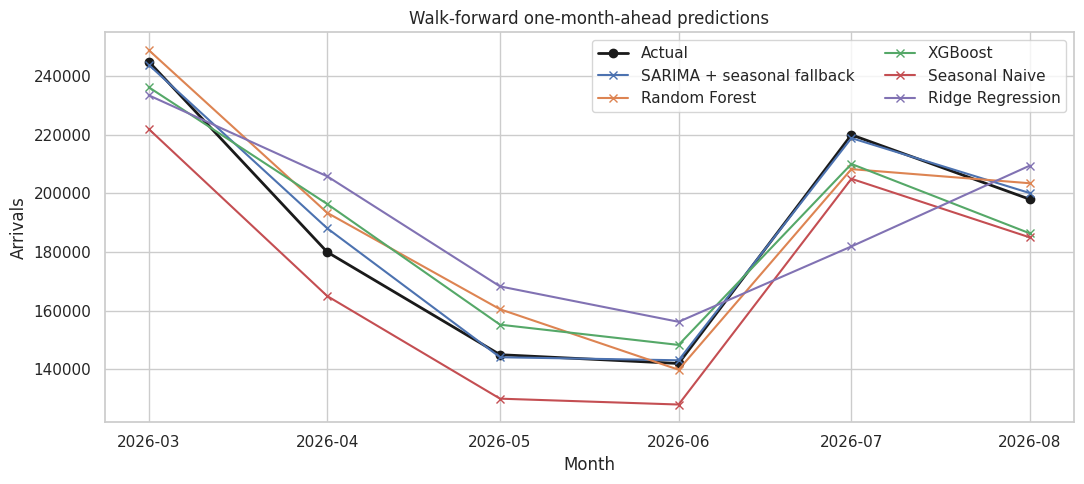

In [35]:
fig,ax=plt.subplots(figsize=(11,5))
obs=all_preds[all_preds.model.eq('Seasonal Naive')]
ax.plot(obs.date,obs.actual,'ko-',label='Actual',linewidth=2)
for name in comparison.model:
    frame=model_results[name]
    ax.plot(frame.date,frame.prediction,marker='x',label=name)
ax.legend(ncol=2);ax.set(title='Walk-forward one-month-ahead predictions',xlabel='Month',ylabel='Arrivals')
plt.tight_layout();plt.savefig(OUT/'walkforward_predictions.png',dpi=180);plt.show()

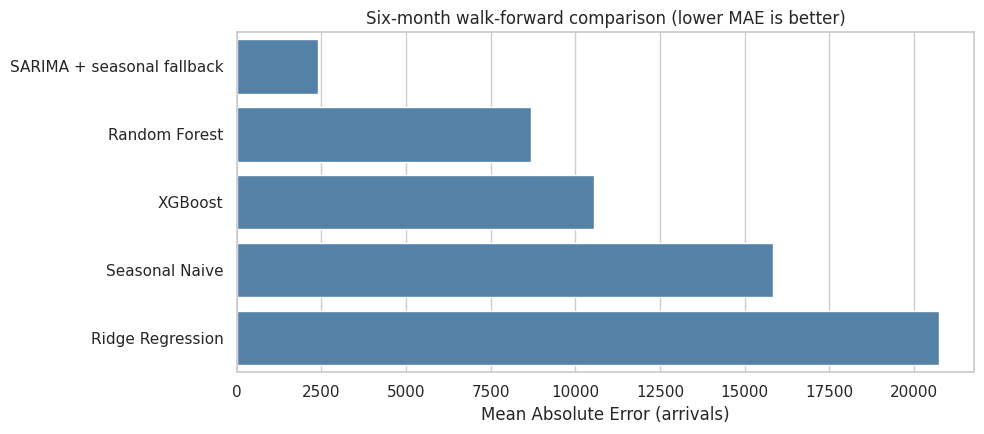

In [36]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=comparison, x='MAE', y='model', color='steelblue', ax=ax)
ax.set(title='Six-month walk-forward comparison (lower MAE is better)',
       ylabel='', xlabel='Mean Absolute Error (arrivals)')
plt.tight_layout()
plt.savefig(OUT/'model_mae_comparison.png', dpi=180)
plt.show()

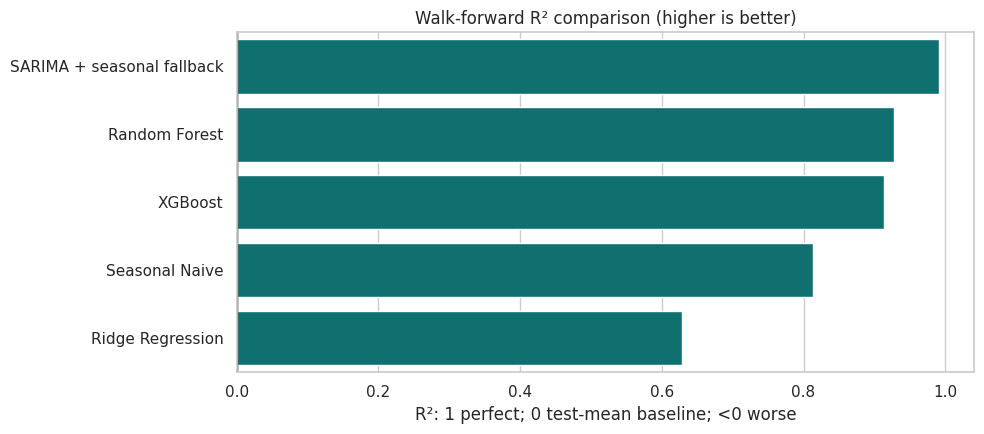

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=comparison.sort_values('R2', ascending=False),
            x='R2', y='model', color='teal', ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Walk-forward R² comparison (higher is better)',
       ylabel='', xlabel='R²: 1 perfect; 0 test-mean baseline; <0 worse')
plt.tight_layout()
plt.savefig(OUT/'model_r2_comparison.png', dpi=180)
plt.show()

## 17 · XGBoost feature importance

In [38]:
cutoff=len(ts)-HOLDOUT
train=X.iloc[:cutoff].assign(y=ts.iloc[:cutoff]).dropna()
importance_model=clone(xgb)
importance_model.fit(train[FEATURES],train.y)
heldout_x=X.iloc[cutoff:][FEATURES]
heldout_y=ts.iloc[cutoff:]
print('XGBoost trained on',len(train),'feature-complete past months; evaluated on',len(heldout_y),'held-out months.')

XGBoost trained on 38 feature-complete past months; evaluated on 6 held-out months.


In [39]:
perm=permutation_importance(importance_model,heldout_x,heldout_y,
                            scoring='neg_mean_absolute_error',n_repeats=20,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':FEATURES,'mae_increase':perm.importances_mean,
                         'std':perm.importances_std}).sort_values('mae_increase',ascending=False)
display(importance.round(2))
importance.to_csv(OUT/'xgboost_permutation_importance.csv',index=False)

,feature,mae_increase,std
7,lag_12,19098.91,6441.34
3,lag_1,3162.85,2385.47
2,month_cos,2882.03,1419.28
5,lag_3,1563.02,809.26
9,rolling_mean_6,1218.24,711.18
1,month_sin,282.90,2089.49
4,lag_2,103.85,320.94
6,lag_6,9.10,101.20
0,trend,0.00,0.00
8,rolling_mean_3,-16.08,20.65


In [ ]:
fig,ax=plt.subplots(figsize=(9,5))
sorted_importance=importance.sort_values('mae_increase')
ax.barh(sorted_importance.feature,sorted_importance.mae_increase,xerr=sorted_importance['std'])
ax.axvline(0,color='black',linewidth=0.7)
ax.set(title='XGBoost permutation feature importance',xlabel='Increase in MAE (arrivals)')
plt.tight_layout();plt.savefig(OUT/'feature_importance.png',dpi=180);plt.show()

## 18 · Six-month future forecast using the winning model

In [40]:
best_name = comparison.iloc[0]['model']
estimators = {'Ridge Regression':ridge, 'Random Forest':rf, 'XGBoost':xgb}
HORIZON = 6
print('Selected by lowest six-month one-step MAE:', best_name)
print('Selected model R²:', f"{comparison.iloc[0]['R2']:.4f}")
if best_name == 'SARIMA + seasonal fallback':
    print('Selected strategy uses converged SARIMA when possible, otherwise seasonal baseline.')

Selected by lowest six-month one-step MAE: SARIMA + seasonal fallback
Selected model R²: 0.9911
Selected strategy uses converged SARIMA when possible, otherwise seasonal baseline.


In [41]:
forecast = []
if best_name == 'SARIMA + seasonal fallback':
    stable = fit_stable_sarima(ts)
    if stable is not None:
        _, order, seasonal, fitted = stable
        values = np.maximum(0, np.asarray(fitted.forecast(HORIZON), dtype=float))
        method = f'SARIMA {order} x {seasonal}'
    else:
        values = np.array([float(ts.iloc[-12 + k]) for k in range(HORIZON)])
        method = 'seasonal baseline (SARIMA did not converge)'
    dates = pd.date_range(ts.index[-1] + pd.offsets.MonthBegin(1), periods=HORIZON, freq='MS')
    forecast = [{'date': d, 'prediction': round(v), 'model': best_name,
                 'method': method} for d,v in zip(dates, values)]
else:
    fitted = None
    if best_name in estimators:
        fitted = clone(estimators[best_name])
        training = X.assign(y=ts).dropna()
        fitted.fit(training[FEATURES], training.y)
    extended = ts.copy()
    for _ in range(HORIZON):
        date = extended.index[-1] + pd.offsets.MonthBegin(1)
        candidate = extended.reindex(extended.index.append(pd.DatetimeIndex([date])))
        x_next = build_features(candidate).loc[[date], FEATURES]
        pred = float(x_next.lag_12.iloc[0]) if fitted is None else float(fitted.predict(x_next)[0])
        pred = max(0, pred)
        extended.loc[date] = pred
        forecast.append({'date': date, 'prediction': round(pred),
                         'model': best_name, 'method': 'recursive future prediction'})
future = pd.DataFrame(forecast)
display(future)
future.to_csv(OUT/'six_month_forecast.csv', index=False)

,date,prediction,model,method
0,2026-09-01,172776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"
1,2026-10-01,167776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"
2,2026-11-01,227776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"
3,2026-12-01,287776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"
4,2027-01-01,260776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"
5,2027-02-01,272776,SARIMA + seasonal fallback,"SARIMA (0, 1, 1) x (0, 1, 0, 12)"


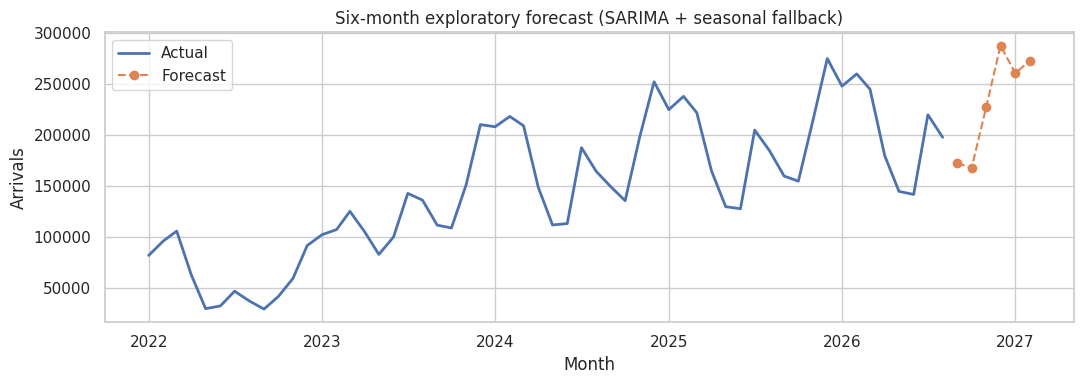

In [42]:
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(ts.index,ts.values,label='Actual',linewidth=2)
ax.plot(future.date,future.prediction,'o--',label='Forecast')
ax.set(title=f'Six-month exploratory forecast ({best_name})',xlabel='Month',ylabel='Arrivals')
ax.legend();plt.tight_layout();plt.savefig(OUT/'six_month_forecast.png',dpi=180);plt.show()

## 19 · Findings and reproducible export

In [43]:
peak=monthly.loc[monthly.total_arrivals.idxmax()]
top=country_summary.iloc[0]
lines=[
    '# Sri Lanka Tourism - concise findings',
    f'Observed period: {monthly.date.min():%B %Y} to {monthly.date.max():%B %Y} ({len(monthly)} months).',
    f'Peak reported arrivals: {peak.total_arrivals:,.0f} in {peak.date:%B %Y}.',
    f'Largest recorded origin market: {top.country} ({top.arrivals:,.0f} arrivals across {int(top.months_recorded)} months).',
    f'Best walk-forward model by MAE: {best_name} ({comparison.iloc[0].MAE:,.1f} arrivals; R² {comparison.iloc[0].R2:.4f}).',
    f'Highest R²: {comparison.loc[comparison.R2.idxmax(), "model"]} ({comparison.R2.max():.4f}).',
    f'SARIMA seasonal fallback used in {int((sarima_detail.forecast_method=="seasonal_naive_fallback").sum())} of {HOLDOUT} validation months.',
    f'Tested months: {HOLDOUT}; all model rankings are provisional with short validation history.',
    'Revenue is estimated; country-row coverage varies; correlation is not causation.',
    'Six-month extrapolations are not independently multi-horizon backtested.'
]
(OUT/'findings_summary.md').write_text('\n\n'.join(lines),encoding='utf-8')
display(Markdown('\n\n'.join(lines)))

# Sri Lanka Tourism - concise findings

Observed period: January 2022 to August 2026 (56 months).

Peak reported arrivals: 275,000 in December 2025.

Largest recorded origin market: Other Countries (3,051,362 arrivals across 56 months).

Best walk-forward model by MAE: SARIMA + seasonal fallback (2,402.9 arrivals; R² 0.9911).

Highest R²: SARIMA + seasonal fallback (0.9911).

SARIMA seasonal fallback used in 0 of 6 validation months.

Tested months: 6; all model rankings are provisional with short validation history.

Revenue is estimated; country-row coverage varies; correlation is not causation.

Six-month extrapolations are not independently multi-horizon backtested.